In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [3]:
df = pd.read_csv("Nike_Sales_Uncleaned.csv")
df.head(10)

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,NaN,NaN,0.47,0.0,2024-03-09,Online,bengaluru,-770.45
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.93,NaN,0.0,2024-07-09,Retail,Hyd,-112.53
2,2002,Women,Soccer,Premier III,M,4.0,NaN,NaN,0.0,NaN,Retail,Mumbai,3337.34
3,2003,Kids,Lifestyle,Blazer Mid,L,NaN,9673.57,NaN,0.0,04-10-2024,Online,Pune,3376.85
4,2004,Kids,Running,React Infinity,XL,NaN,NaN,NaN,0.0,2024/09/12,Retail,Delhi,187.89
5,2005,Women,Training,Flex Trainer,M,1.0,7363.96,NaN,0.0,NaN,Retail,Delhi,1415.98
6,2006,Men,Training,SuperRep Go,M,NaN,6819.78,NaN,0.0,04-06-2025,Online,Bangalore,1802.09
7,2007,Kids,Training,SuperRep Go,M,1.0,NaN,0.32,0.0,NaN,Retail,Bangalore,2928.36
8,2008,Women,Soccer,Premier III,11,-1.0,NaN,NaN,0.0,11-10-2024,Online,Hyderabad,-731.18
9,2009,Men,Soccer,Mercurial Superfly,M,4.0,NaN,NaN,0.0,NaN,Online,Pune,3929.61


In [4]:
df.dtypes

Order_ID              int64
Gender_Category      object
Product_Line         object
Product_Name         object
Size                 object
Units_Sold          float64
MRP                 float64
Discount_Applied    float64
Revenue             float64
Order_Date           object
Sales_Channel        object
Region               object
Profit              float64
dtype: object

In [5]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df['Revenue'] = df['Revenue'].replace('[\$,]', '', regex=True)
df['Revenue'] = pd.to_numeric(df['Revenue'])

In [6]:
df.isna().sum()

Order_ID               0
Gender_Category        0
Product_Line           0
Product_Name           0
Size                 510
Units_Sold          1235
MRP                 1254
Discount_Applied    1668
Revenue                0
Order_Date          1900
Sales_Channel          0
Region                 0
Profit                 0
dtype: int64

In [7]:
#droping miseing date
df = df.dropna(subset=['Order_Date'])
df.isna().sum()

Order_ID              0
Gender_Category       0
Product_Line          0
Product_Name          0
Size                127
Units_Sold          294
MRP                 302
Discount_Applied    413
Revenue               0
Order_Date            0
Sales_Channel         0
Region                0
Profit                0
dtype: int64

In [8]:
#Using median
df['Units_Sold'] = df['Units_Sold'].fillna(df['Units_Sold'].median())
df['MRP'] = df['MRP'].fillna(df['MRP'].median())
df['Discount_Applied'] = df['Discount_Applied'].fillna(df['Discount_Applied'].median())
df.isna().sum()

Order_ID              0
Gender_Category       0
Product_Line          0
Product_Name          0
Size                127
Units_Sold            0
MRP                   0
Discount_Applied      0
Revenue               0
Order_Date            0
Sales_Channel         0
Region                0
Profit                0
dtype: int64

In [9]:
#filling with most commen value
df['Size'] = df['Size'].fillna(df['Size'].mode()[0])
df.isna().sum()

Order_ID            0
Gender_Category     0
Product_Line        0
Product_Name        0
Size                0
Units_Sold          0
MRP                 0
Discount_Applied    0
Revenue             0
Order_Date          0
Sales_Channel       0
Region              0
Profit              0
dtype: int64

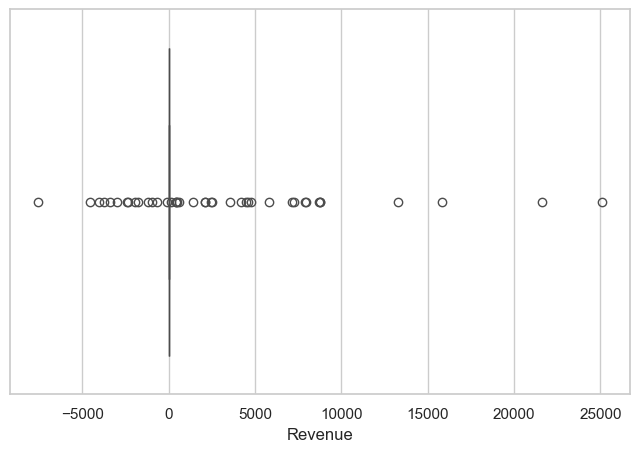

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Revenue'])
plt.show()

In [11]:
Q1 = df['Revenue'].quantile(0.25)
Q3 = df['Revenue'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Revenue'] < lower) | (df['Revenue'] > upper)]
outliers.head(15)

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
31,2031,Men,Soccer,Premier III,L,4.0,3493.04,0.82,2514.99,2024-05-09,Online,Delhi,350.70
135,2135,Men,Basketball,Zoom Freak,L,2.0,9106.61,0.74,4735.44,2024-11-03,Retail,hyderbad,2422.38
222,2222,Men,Training,ZoomX Invincible,XL,2.0,8897.19,0.11,15837.00,2024-12-21,Retail,Mumbai,2821.69
234,2234,Men,Training,Flex Trainer,L,4.0,6189.10,1.12,-2970.77,2024-12-21,Retail,bengaluru,2085.62
248,2248,Men,Training,Metcon 7,M,4.0,8249.96,0.24,25079.88,2024-01-16,Online,bengaluru,1625.14
264,2264,Men,Training,ZoomX Invincible,L,4.0,5622.32,1.08,-1799.14,2024-04-22,Retail,bengaluru,1248.25
432,2432,Women,Basketball,Zoom Freak,L,1.0,3036.61,0.86,425.13,2024-10-26,Online,Mumbai,3754.30
448,2003,Women,Lifestyle,Waffle One,XL,2.0,8516.45,0.22,13285.66,2023-09-30,Online,Kolkata,1764.52
460,2460,Women,Basketball,Zoom Freak,XL,2.0,5482.96,0.35,7127.85,2024-11-04,Online,Kolkata,-823.80
487,2487,Men,Running,Air Zoom,L,3.0,5881.13,0.80,3528.68,2025-03-31,Online,hyderbad,2108.40


In [12]:
df_no_outliers = df[(df['Revenue'] >= lower) & (df['Revenue'] <= upper)]
print("Original shape: ",df.shape)
print("After removing outliers: ",df_no_outliers.shape)

Original shape:  (600, 13)
After removing outliers:  (559, 13)


In [13]:
num_cols = ['Units_Sold','MRP','Discount_Applied','Revenue','Profit']
X = df[num_cols]

In [14]:
# min and max
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()
X_minmax = minmax.fit_transform(X)

X_minmax = pd.DataFrame(X_minmax, columns=num_cols)
X_minmax.head()

,Units_Sold,MRP,Discount_Applied,Revenue,Profit
0,0.6,0.518838,0.376,0.231656,0.081910
1,0.8,0.363511,0.488,0.231656,0.208610
2,0.6,0.518838,0.488,0.231656,0.029154
3,0.4,0.518838,0.128,0.231656,0.673522
4,0.2,0.518838,0.488,0.231656,0.194525


In [15]:
# Z-Score Normalization
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_zscore = scaler.fit_transform(X)

X_zscore = pd.DataFrame(X_zscore, columns=num_cols)
X_zscore.head()

,Units_Sold,MRP,Discount_Applied,Revenue,Profit
0,0.210018,-0.005658,-0.702335,-0.115731,-1.452279
1,0.997585,-0.774234,-0.021715,-0.115731,-1.012273
2,0.210018,-0.005658,-0.021715,-0.115731,-1.635492
3,-0.577549,-0.005658,-2.209421,-0.115731,0.602284
4,-1.365116,-0.005658,-0.021715,-0.115731,-1.061188


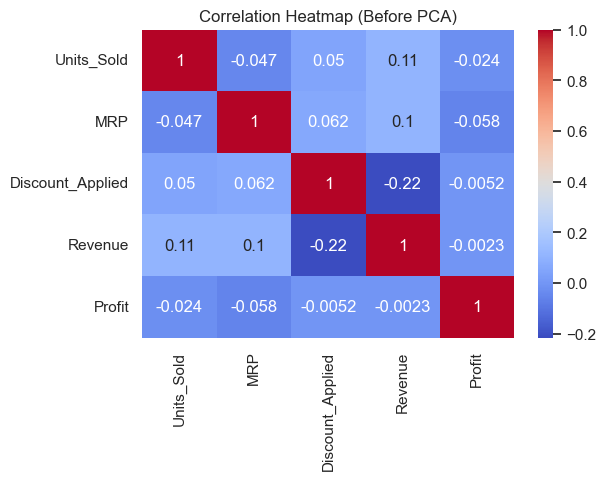

In [16]:
# Check Correlation Before Applying PCA

num_cols = ['Units_Sold','MRP','Discount_Applied','Revenue','Profit']

corr_matrix = df[num_cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap (Before PCA)")
plt.show()

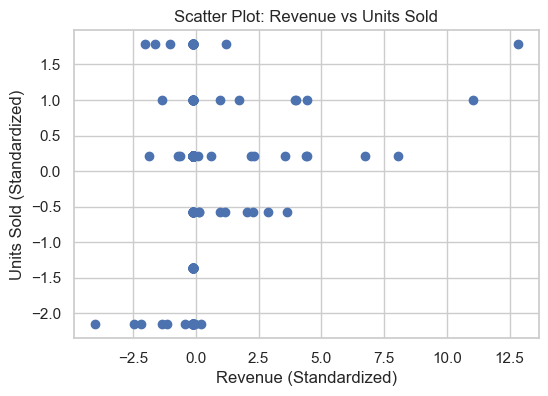

In [20]:
from sklearn.preprocessing import StandardScaler

num_cols = ['Units_Sold','MRP','Discount_Applied','Revenue','Profit']

scaler = StandardScaler()
df_standardized = pd.DataFrame(scaler.fit_transform(df[num_cols]),
                               columns=num_cols)



plt.figure(figsize=(6,4))
plt.scatter(df_standardized['Revenue'], df_standardized['Units_Sold'])

plt.xlabel("Revenue (Standardized)")
plt.ylabel("Units Sold (Standardized)")
plt.title("Scatter Plot: Revenue vs Units Sold")

plt.show()

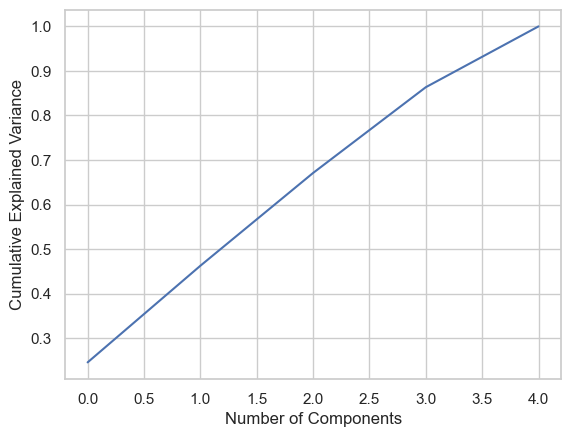

In [18]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_zscore)

plt.figure()
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()